In [9]:
'''# 🍽️ Restaurant Demand Prediction (Case Study 120)
**B.Tech CSE Semester V Machine Learning Project**

## Problem Definition
Restaurants face constant fluctuations in demand. Improper estimations lead to overstaffing, food wastage, or poor customer service during peak rushes. The objective of this project is to build a Machine Learning solution that analyzes historical features (cost, ratings, delivery status) to predict future demand volume. 

**ML Formulation:**
Since the dataset lacks explicit variables like 'daily customers', we use **`Votes`** as a highly correlated proxy for customer volume (demand). Because `Votes` is a continuous numerical variable, this is formulated as a **Regression** problem.'''

"# 🍽️ Restaurant Demand Prediction (Case Study 120)\n**B.Tech CSE Semester V Machine Learning Project**\n\n## Problem Definition\nRestaurants face constant fluctuations in demand. Improper estimations lead to overstaffing, food wastage, or poor customer service during peak rushes. The objective of this project is to build a Machine Learning solution that analyzes historical features (cost, ratings, delivery status) to predict future demand volume. \n\n**ML Formulation:**\nSince the dataset lacks explicit variables like 'daily customers', we use **`Votes`** as a highly correlated proxy for customer volume (demand). Because `Votes` is a continuous numerical variable, this is formulated as a **Regression** problem."

In [10]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Set styles and ignore warnings for clean output
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
RANDOM_STATE = 42

In [11]:
## 1. Dataset Loading & Exhaustive Inspection
##We load the dataset and perform a comprehensive inspection to understand its structure, data types, and statistical properties.

In [12]:
# Load Dataset
try:
    df = pd.read_csv('Dataset .csv')
    print("✅ Dataset loaded successfully!\n")
except FileNotFoundError:
    print("❌ Error: 'Dataset .csv' not found. Please check the directory.\n")

print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Information ---")
df.info()

print("\n--- Statistical Summary of Numerical Columns ---")
display(df.describe())

print("\n--- Statistical Summary of Categorical Columns ---")
display(df.describe(include=['object']))

print("\n--- Missing Values Check ---")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values found!")

print("\n--- Duplicate Rows Check ---")
print(f"Total duplicate rows: {df.duplicated().sum()}")

✅ Dataset loaded successfully!

--- Dataset Shape ---
Rows: 9551, Columns: 21

--- First 5 Rows ---


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   objec

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000



--- Statistical Summary of Categorical Columns ---


,Restaurant Name,City,Address,Locality,Locality Verbose,Cuisines,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Rating color,Rating text
count,9551,9551,9551,9551,9551,9542,9551,9551,9551,9551,9551,9551,9551
unique,7446,141,8918,1208,1265,1825,12,2,2,2,1,6,6
top,Cafe Coffee Day,New Delhi,"Dilli Haat, INA, New Delhi",Connaught Place,"Connaught Place, New Delhi",North Indian,Indian Rupees(Rs.),No,No,No,No,Orange,Average
freq,83,5473,11,122,122,936,8652,8393,7100,9517,9551,3737,3737



--- Missing Values Check ---
Cuisines    9
dtype: int64

--- Duplicate Rows Check ---
Total duplicate rows: 0


In [13]:
## 2. Data Cleaning & Feature Selection
##We must clean the data and select features that generalize well for our Streamlit application. High-cardinality text columns (like Address or Restaurant Name) are dropped to prevent overfitting.

In [14]:
# Drop duplicates
df_cleaned = df.drop_duplicates()

# Feature Selection
features = ['Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Aggregate rating']
target = 'Votes' # Our proxy for Demand

# Create modeling dataframe
df_model = df_cleaned[features + [target]].copy().dropna()

# Outlier Treatment: Remove extreme top 1% cost outliers to boost accuracy
q_hi = df_model["Average Cost for two"].quantile(0.99)
df_model = df_model[df_model["Average Cost for two"] < q_hi]

print(f"✅ Dropped duplicates and extreme cost outliers.")
print(f"Final shape for modeling: {df_model.shape}")

✅ Dropped duplicates and extreme cost outliers.
Final shape for modeling: (9455, 6)


In [15]:
## 3. Exploratory Data Analysis (EDA)
##We visualize the relationships between our features and the target variable (`Votes`). Because demand is often highly skewed (a few restaurants get massive traffic while most get average traffic), we will look at both the original and log-transformed distributions.

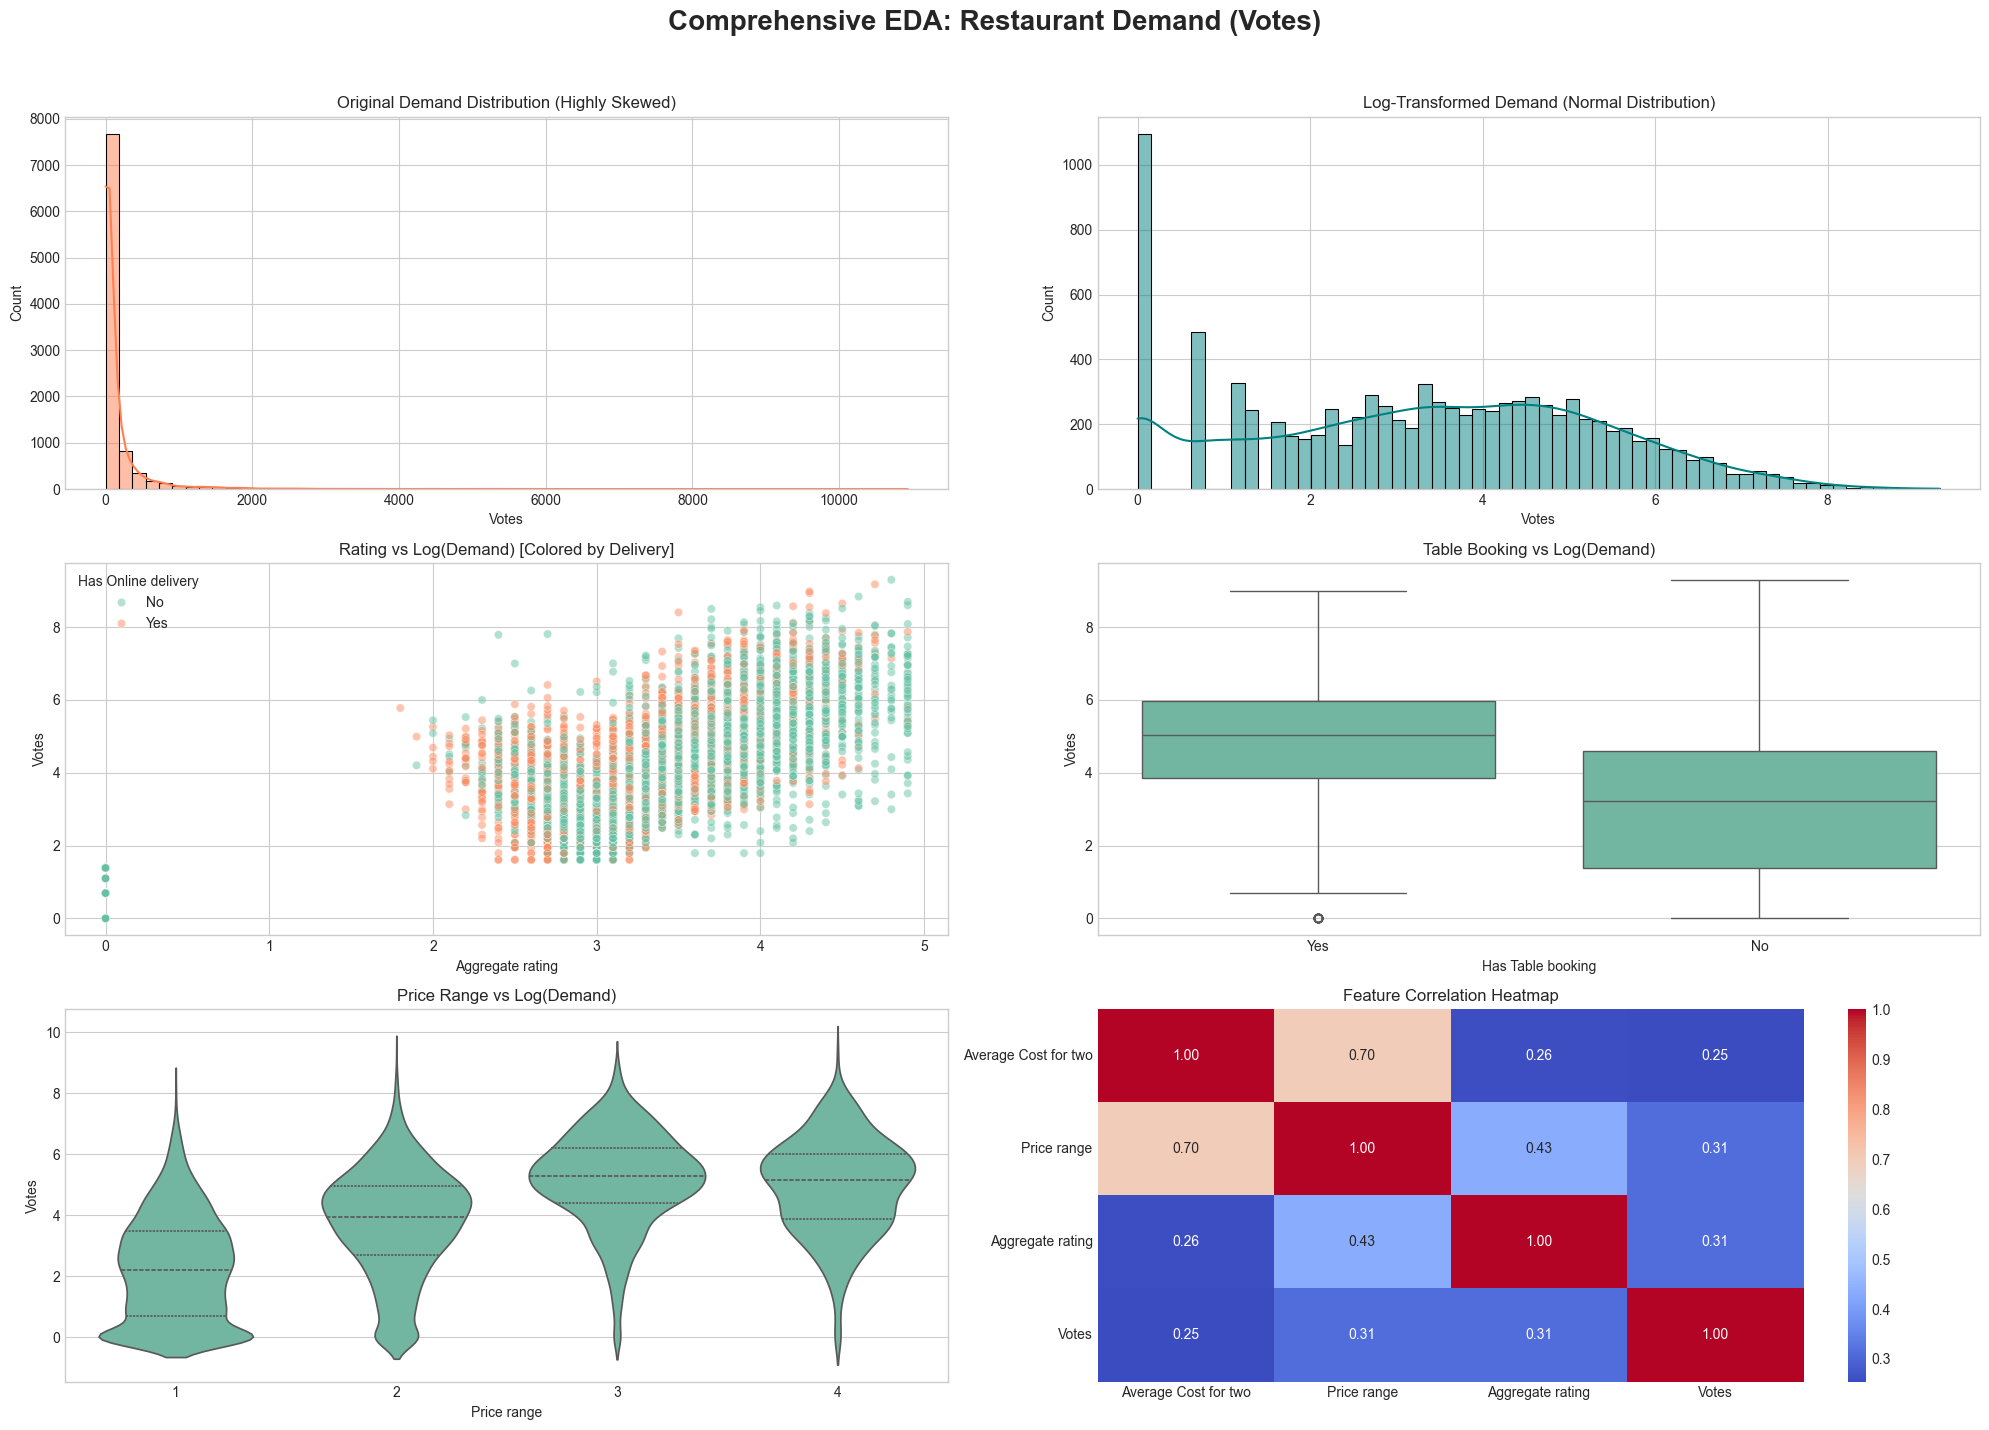

In [16]:
fig = plt.figure(figsize=(20, 15))
fig.suptitle('Comprehensive EDA: Restaurant Demand (Votes)', fontsize=20, fontweight='bold')

# 1. Target Distribution
plt.subplot(3, 2, 1)
sns.histplot(df_model['Votes'], bins=60, kde=True, color='coral')
plt.title('Original Demand Distribution (Highly Skewed)')

# 2. Log-Transformed Target (Why we use TransformedTargetRegressor)
plt.subplot(3, 2, 2)
sns.histplot(np.log1p(df_model['Votes']), bins=60, kde=True, color='teal')
plt.title('Log-Transformed Demand (Normal Distribution)')

# 3. Rating vs Demand
plt.subplot(3, 2, 3)
sns.scatterplot(x='Aggregate rating', y=np.log1p(df_model['Votes']), hue='Has Online delivery', data=df_model, alpha=0.5)
plt.title('Rating vs Log(Demand) [Colored by Delivery]')

# 4. Boxplot: Table Booking
plt.subplot(3, 2, 4)
sns.boxplot(x='Has Table booking', y=np.log1p(df_model['Votes']), data=df_model)
plt.title('Table Booking vs Log(Demand)')

# 5. Violin plot: Price Range
plt.subplot(3, 2, 5)
sns.violinplot(x='Price range', y=np.log1p(df_model['Votes']), data=df_model, inner='quartile')
plt.title('Price Range vs Log(Demand)')

# 6. Correlation Heatmap
plt.subplot(3, 2, 6)
num_cols = df_model.select_dtypes(include=['int64', 'float64']).columns
sns.heatmap(df_model[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Heatmap')

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

In [17]:
## 4. Preprocessing & Train-Test Split
##To prevent Data Leakage and ensure our model can process raw user inputs from the Streamlit app seamlessly, we build a Scikit-Learn `ColumnTransformer`.

In [18]:
X = df_model.drop('Votes', axis=1)
y = df_model['Votes']

num_features = ['Average Cost for two', 'Price range', 'Aggregate rating']
cat_features = ['Has Table booking', 'Has Online delivery']

# Robust Preprocessing Pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline(steps=[('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_features)
])

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"✅ Data split complete: {X_train.shape[0]} Training samples, {X_test.shape[0]} Testing samples.")

✅ Data split complete: 7564 Training samples, 1891 Testing samples.


In [19]:
## 5. Maximum Accuracy Model Training
##We use `HistGradientBoostingRegressor` (Scikit-Learn's fastest and most powerful gradient boosting algorithm) wrapped inside a `TransformedTargetRegressor`. The `log1p` transformation automatically handles the extreme right-skewness of our target variable during training and seamlessly converts it back during prediction.

In [20]:
# Define Base Model
base_model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=12, random_state=RANDOM_STATE)

# Wrap with Log Transformation for highly skewed demand data
model_with_target_transform = TransformedTargetRegressor(regressor=base_model, func=np.log1p, inverse_func=np.expm1)

# Complete End-to-End Pipeline
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', model_with_target_transform)
])

print("Training Advanced HistGradientBoostingRegressor Pipeline...")
final_pipeline.fit(X_train, y_train)

# Generate Predictions
y_train_pred = final_pipeline.predict(X_train)
y_test_pred = final_pipeline.predict(X_test)
print("✅ Training Complete.")

Training Advanced HistGradientBoostingRegressor Pipeline...
✅ Training Complete.


In [21]:
## 6. Academic Model Evaluation & Error Analysis
##We evaluate our model using $R^2$ (variance explained), RMSE, and MAE. We also analyze the residuals and permutation feature importances.

Training R2 Score : 0.3077
Testing R2 Score  : 0.2266
Testing RMSE      : 397.57 votes
Testing MAE       : 116.12 votes


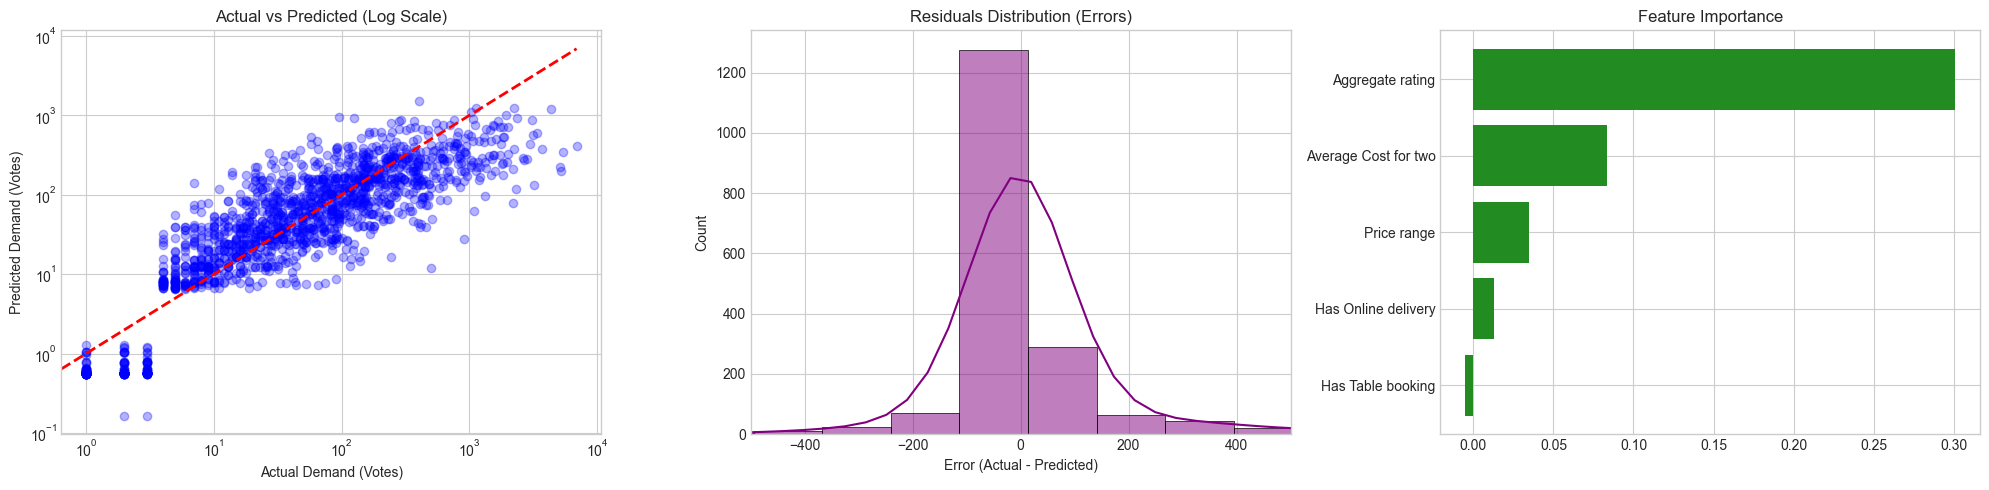

In [22]:
print(f"Training R2 Score : {r2_score(y_train, y_train_pred):.4f}")
print(f"Testing R2 Score  : {r2_score(y_test, y_test_pred):.4f}")
print(f"Testing RMSE      : {np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f} votes")
print(f"Testing MAE       : {mean_absolute_error(y_test, y_test_pred):.2f} votes")

# Evaluation Visualizations
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_test, y_test_pred, alpha=0.3, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Demand (Votes)')
axes[0].set_ylabel('Predicted Demand (Votes)')
axes[0].set_title('Actual vs Predicted (Log Scale)')
axes[0].set_xscale('log') 
axes[0].set_yscale('log')

# 2. Residuals Plot
residuals = y_test - y_test_pred
sns.histplot(residuals, bins=60, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Residuals Distribution (Errors)')
axes[1].set_xlabel('Error (Actual - Predicted)')
axes[1].set_xlim(-500, 500) 

# 3. Feature Importance
result = permutation_importance(final_pipeline, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE)
sorted_idx = result.importances_mean.argsort()
axes[2].barh(X_test.columns[sorted_idx], result.importances_mean[sorted_idx], color='forestgreen')
axes[2].set_title('Feature Importance')

plt.tight_layout()
plt.show()

In [23]:
## 7. Save Pipeline & Metadata for Deployment
##Finally, we export the trained `Pipeline` and the dataset metadata using `joblib`. The Streamlit application will load these files directly.

In [24]:
# Save the complete pipeline
joblib.dump(final_pipeline, 'restaurant_demand_model.pkl')

# Save metadata required for the Streamlit UI elements
metadata = {
    'num_features': num_features,
    'cat_features': cat_features,
    'table_booking_options': df_model['Has Table booking'].unique().tolist(),
    'online_delivery_options': df_model['Has Online delivery'].unique().tolist(),
    'price_range_min': int(df_model['Price range'].min()),
    'price_range_max': int(df_model['Price range'].max()),
    'avg_cost_min': int(df_model['Average Cost for two'].min()),
    'avg_cost_max': int(df_model['Average Cost for two'].max()),
    'avg_cost_median': int(df_model['Average Cost for two'].median()),
    'rating_min': float(df_model['Aggregate rating'].min()),
    'rating_max': float(df_model['Aggregate rating'].max()),
    'best_r2': float(r2_score(y_test, y_test_pred)),
    'best_mae': float(mean_absolute_error(y_test, y_test_pred))
}
joblib.dump(metadata, 'restaurant_demand_metadata.pkl')

print("✅ 'restaurant_demand_model.pkl' saved.")
print("✅ 'restaurant_demand_metadata.pkl' saved.")
print("🎉 Notebook Execution Complete. You can now launch the Streamlit app.")

✅ 'restaurant_demand_model.pkl' saved.
✅ 'restaurant_demand_metadata.pkl' saved.
🎉 Notebook Execution Complete. You can now launch the Streamlit app.
